# CNN for cat vs dog

part 2. small cnn in keras that tells cats from dogs. data is the kaggle cat/dog zip from canvas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import warnings
warnings.filterwarnings("ignore")
import random
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image_dataset_from_directory

random.seed(0)
np.random.seed(0)
tf.random.set_seed(0)

IMG_SIZE = (200, 180)
BATCH_SIZE = 32
EPOCHS = 10
DATA_FRACTION = 0.30   # cpu only, so train on 30% of the train batches like in class

## prepare the data

the zip has a `train` folder and a `test` folder, all images in one place and the label is in the file name (`cat.12.jpg`, `dog.7.jpg`).
keras wants one folder per class, so i sort them into `dataset/train`, `dataset/validation`, `dataset/test`, each with `cat` and `dog` inside.
validation = 20% of the kaggle train images, test = the kaggle test folder.

In [2]:
ZIP_PATH = "../../data_from_kaggle.zip"
DATA_DIR = "dataset"

if not os.path.exists(DATA_DIR):
    z = zipfile.ZipFile(ZIP_PATH)
    files = [n for n in z.namelist() if n.endswith(".jpg")]
    train_files = [f for f in files if "/train/" in f]
    test_files = [f for f in files if "/test/" in f]

    random.shuffle(train_files)
    n_val = int(len(train_files) * 0.2)
    splits = {"validation": train_files[:n_val], "train": train_files[n_val:], "test": test_files}

    for split, names in splits.items():
        for name in names:
            fname = os.path.basename(name)
            label = fname.split(".")[0]          # cat or dog
            out = os.path.join(DATA_DIR, split, label)
            os.makedirs(out, exist_ok=True)
            with z.open(name) as src, open(os.path.join(out, fname), "wb") as dst:
                shutil.copyfileobj(src, dst)
    z.close()

for split in ["train", "validation", "test"]:
    n_cat = len(os.listdir(os.path.join(DATA_DIR, split, "cat")))
    n_dog = len(os.listdir(os.path.join(DATA_DIR, split, "dog")))
    print(f"{split}: {n_cat} cats, {n_dog} dogs")

train: 7958 cats, 8034 dogs
validation: 2042 cats, 1955 dogs
test: 2500 cats, 2500 dogs


load them as tf datasets. labels are 0 = cat, 1 = dog

In [3]:
train_ds = image_dataset_from_directory(DATA_DIR + "/train", image_size=IMG_SIZE,
                                        batch_size=BATCH_SIZE, label_mode="binary", shuffle=True, seed=0)
val_ds = image_dataset_from_directory(DATA_DIR + "/validation", image_size=IMG_SIZE,
                                      batch_size=BATCH_SIZE, label_mode="binary", shuffle=False)
test_ds = image_dataset_from_directory(DATA_DIR + "/test", image_size=IMG_SIZE,
                                       batch_size=BATCH_SIZE, label_mode="binary", shuffle=False)
class_names = train_ds.class_names
print(class_names)

n_train_batches = tf.data.experimental.cardinality(train_ds).numpy()
train_small = train_ds.take(max(1, int(n_train_batches * DATA_FRACTION)))
print("train batches:", n_train_batches, " using:", int(n_train_batches * DATA_FRACTION))

Found 15992 files belonging to 2 classes.


Found 3997 files belonging to 2 classes.


Found 5000 files belonging to 2 classes.


['cat', 'dog']
train batches: 500  using: 150


some training pics

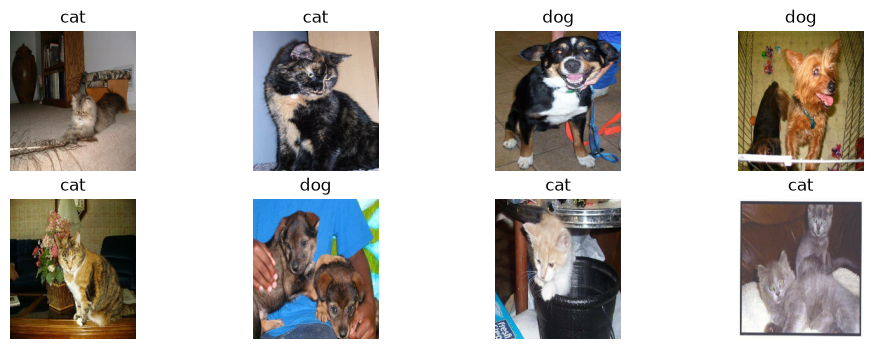

In [4]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(12, 4))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
    plt.show()

## the cnn

3 conv + maxpool blocks, then global avg pooling, a dense layer, dropout and 1 sigmoid output (prob of dog).
pixels get scaled to 0-1 inside the model with Rescaling.

In [5]:
model = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 rescaling (Rescaling)       (None, 200, 180, 3)       0         


 conv2d (Conv2D)             (None, 198, 178, 32)      896       


 max_pooling2d (MaxPooling2  (None, 99, 89, 32)        0         


... (12 outputs left out)

Total params: 109889 (429.25 KB)


Trainable params: 109889 (429.25 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


## train (10 epochs)

In [6]:
def show(epoch, logs):
    print(f"epoch {epoch+1}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}  "
          f"val loss {logs['val_loss']:.4f}  val acc {logs['val_accuracy']:.4f}")

hist = model.fit(train_small.prefetch(tf.data.AUTOTUNE),
                 validation_data=val_ds.prefetch(tf.data.AUTOTUNE),
                 epochs=EPOCHS, verbose=0,
                 callbacks=[keras.callbacks.LambdaCallback(on_epoch_end=show)])

epoch 1  loss 0.6885  acc 0.5225  val loss 0.6593  val acc 0.5824


epoch 2  loss 0.6598  acc 0.5950  val loss 0.6567  val acc 0.5872


epoch 3  loss 0.6560  acc 0.6058  val loss 0.6466  val acc 0.6172


epoch 4  loss 0.6372  acc 0.6256  val loss 0.6279  val acc 0.6355


epoch 5  loss 0.6288  acc 0.6496  val loss 0.6118  val acc 0.6575


epoch 6  loss 0.6090  acc 0.6671  val loss 0.5969  val acc 0.6730


epoch 7  loss 0.5994  acc 0.6712  val loss 0.5923  val acc 0.6840


epoch 8  loss 0.5813  acc 0.6958  val loss 0.5839  val acc 0.6925


epoch 9  loss 0.5804  acc 0.6952  val loss 0.6095  val acc 0.6645


epoch 10  loss 0.5699  acc 0.7038  val loss 0.5689  val acc 0.7035


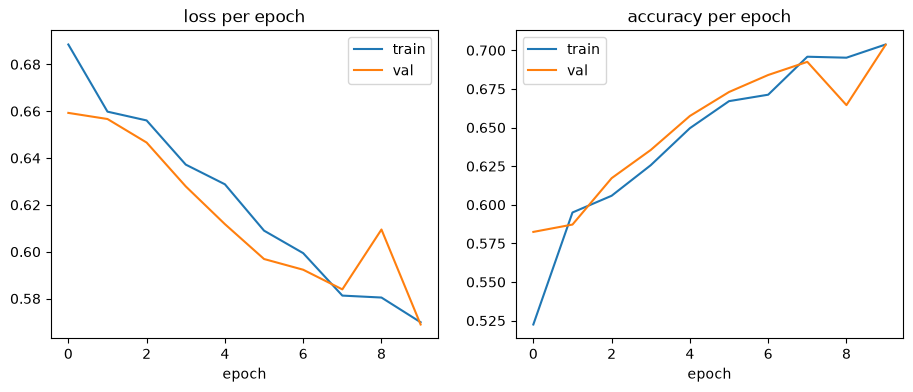

In [7]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("loss per epoch")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("accuracy per epoch")
plt.xlabel("epoch")
plt.legend()
plt.show()

## evaluate on validation and test

In [8]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"validation  loss {val_loss:.4f}  acc {val_acc:.4f}")
print(f"test        loss {test_loss:.4f}  acc {test_acc:.4f}")

validation  loss 0.5689  acc 0.7035
test        loss 0.5677  acc 0.7144


## predictions vs true labels

grab some test images, predict, and show both labels. green = right, red = wrong.

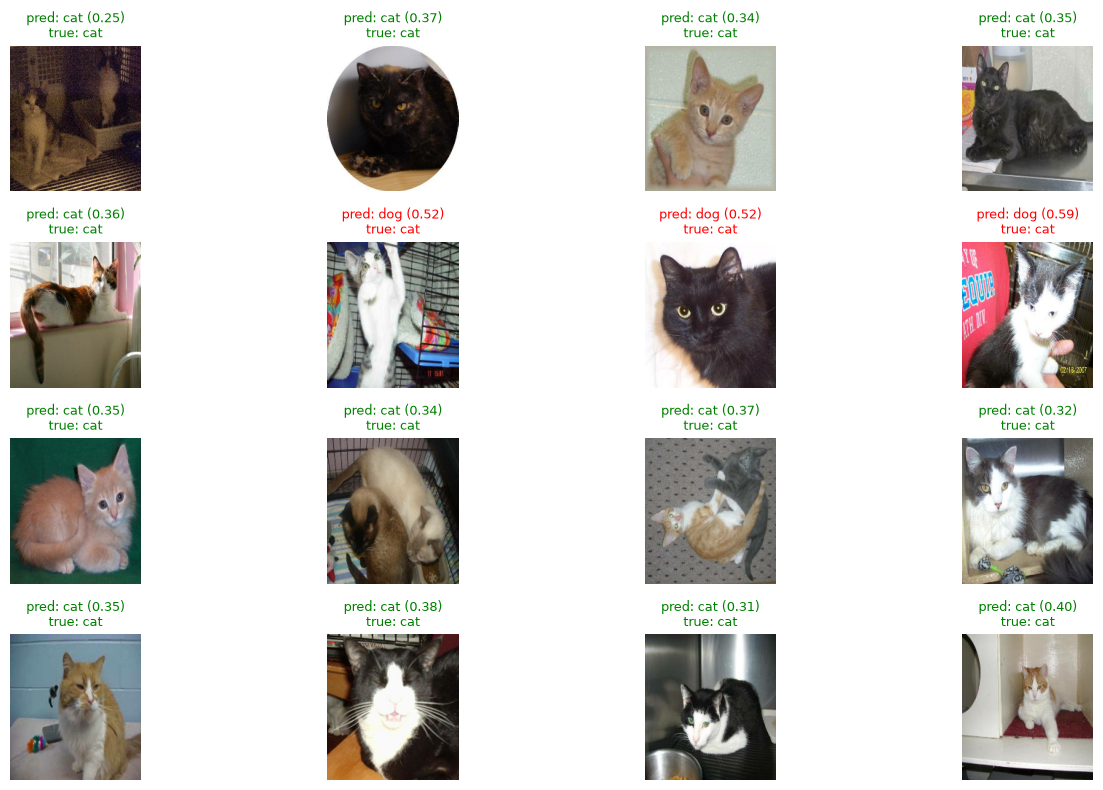

right on these: 13 / 16


In [9]:
test_imgs, test_labels = [], []
for images, labels in test_ds.shuffle(50, seed=1).take(2):
    test_imgs.append(images.numpy())
    test_labels.append(labels.numpy())
test_imgs = np.concatenate(test_imgs)
test_labels = np.concatenate(test_labels).ravel().astype(int)

probs = model.predict(test_imgs, verbose=0).ravel()
preds = (probs > 0.5).astype(int)

idx = np.random.choice(len(test_imgs), 16, replace=False)
plt.figure(figsize=(14, 8))
for k, i in enumerate(idx):
    plt.subplot(4, 4, k + 1)
    plt.imshow(test_imgs[i].astype("uint8"))
    color = "green" if preds[i] == test_labels[i] else "red"
    plt.title(f"pred: {class_names[preds[i]]} ({probs[i]:.2f})\ntrue: {class_names[test_labels[i]]}",
              color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()
print("right on these:", np.sum(preds[idx] == test_labels[idx]), "/ 16")

## wrap up

the cnn trains for 10 epochs and val accuracy climbs along with train accuracy. validation and test accuracy are close to each other, so it does about the same on images it never saw. around 70% is ok for a small cnn trained from scratch on only 30% of the data for 10 epochs, more data or epochs would push it higher.